<a href="https://colab.research.google.com/github/s24bsit044-crypto/At-bash_Ciper./blob/main/yolo11n_seg_bonnetjes_complete_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# YOLO11n-Seg-Bonnetjes — Complete Training Notebook

This notebook downloads the pretrained Hugging Face segmentation model, trains it on your own YOLO segmentation dataset, evaluates it, runs predictions, and downloads the trained weights.

**Runtime:** Google Colab → Runtime → Change runtime type → GPU

**Dataset format:** YOLO segmentation labels (polygon coordinates), not detection-only bounding boxes.


## 1. Install required libraries

In [1]:
!pip install -q -U ultralytics huggingface_hub opencv-python matplotlib pyyaml

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.


## 2. Import libraries and check GPU

In [2]:
import os
import cv2
import yaml
import torch
import shutil
import numpy as np
import matplotlib.pyplot as plt

from ultralytics import YOLO
from huggingface_hub import hf_hub_download
from google.colab import files
from IPython.display import display, Image

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU available: True
GPU: Tesla T4


## 3. Download pretrained model from Hugging Face

In [3]:
MODEL_ID = "ciCic/yolo11n-seg-bonnetjes"
MODEL_FILENAME = "yolo11n-seg-bonnetjes.pt"

model_path = hf_hub_download(
    repo_id=MODEL_ID,
    filename=MODEL_FILENAME
)

print("Pretrained model downloaded:", model_path)

yolo11n-seg-bonnetjes.pt: reconstructing file:   0%|          |  0.00B / 6.00MB            

yolo11n-seg-bonnetjes.pt: downloading bytes:           |  0.00B            

Pretrained model downloaded: /root/.cache/huggingface/hub/models--ciCic--yolo11n-seg-bonnetjes/snapshots/9639848734bb69457309a7b3f06a3b7ed0da855a/yolo11n-seg-bonnetjes.pt


## 4. Load and inspect model

In [4]:
model = YOLO(model_path)
model.info()

print("Task:", model.task)
print("Classes:", model.names)

YOLO11n-seg summary: 203 layers, 2,842,803 parameters, 0 gradients, 9.8 GFLOPs
Task: segment
Classes: {0: 'bonnetje'}


## 5. Optional: test pretrained model on an image

Saving coco128-seg.zip to coco128-seg.zip
Extracting coco128-seg.zip...
Using extracted image: extracted_images/coco128-seg/images/train2017/000000000042.jpg

image 1/1 /content/extracted_images/coco128-seg/images/train2017/000000000042.jpg: 480x640 1 bonnetje, 11.8ms
Speed: 64.8ms preprocess, 11.8ms inference, 48.2ms postprocess per image at shape (1, 3, 480, 640)
Results saved to /content/runs/segment/predict


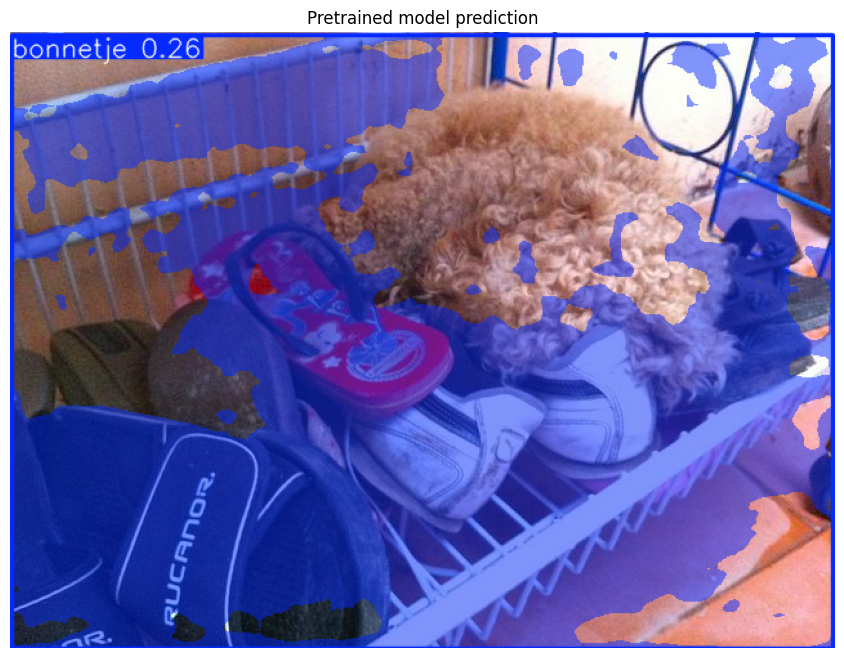

Object 1: bonnetje, confidence=0.256


In [5]:
import zipfile
import glob

uploaded = files.upload()  # Upload an image or a ZIP containing images
image_path = next(iter(uploaded.keys()))

# If a ZIP file is uploaded, extract it first and find the first image
if image_path.endswith('.zip'):
    print(f"Extracting {image_path}...")
    with zipfile.ZipFile(image_path, 'r') as zip_ref:
        zip_ref.extractall('extracted_images')
    # Search for common image formats in the extracted folder
    extracted_images = []
    for ext in ['*.jpg', '*.jpeg', '*.png', '*.webp']:
        extracted_images.extend(glob.glob(f'extracted_images/**/{ext}', recursive=True))

    if not extracted_images:
        raise FileNotFoundError("No images found inside the uploaded ZIP archive.")
    image_path = extracted_images[0]
    print(f"Using extracted image: {image_path}")

results = model.predict(
    source=image_path,
    imgsz=640,
    conf=0.25,
    iou=0.45,
    save=True
)

result = results[0]
annotated = result.plot()

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Pretrained model prediction")
plt.show()

if result.boxes is not None:
    for i, box in enumerate(result.boxes):
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        print(f"Object {i+1}: {model.names[class_id]}, confidence={confidence:.3f}")

## 6. Upload your custom dataset ZIP

Your ZIP should contain a YOLO segmentation dataset, for example:

```text
my_dataset/
├── data.yaml
├── train/
│   ├── images/
│   └── labels/
├── valid/
│   ├── images/
│   └── labels/
└── test/
    ├── images/
    └── labels/
```

YOLO segmentation labels contain a class ID followed by polygon coordinates normalized to 0–1.


In [11]:

from google.colab import files
import zipfile
import os
import yaml

# 1. Upload dataset ZIP
uploaded = files.upload()
zip_path = next(iter(uploaded.keys()))

# 2. Create dataset folder
DATASET_DIR = "/content/my_dataset"
os.makedirs(DATASET_DIR, exist_ok=True)

# 3. Extract ZIP
with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(DATASET_DIR)

print("Dataset extracted to:", DATASET_DIR)

# 4. Find the actual dataset root
dataset_root = None

for root, dirs, filenames in os.walk(DATASET_DIR):
    if (
        "images" in dirs
        and "labels" in dirs
    ):
        dataset_root = root
        break

if dataset_root is None:
    raise FileNotFoundError(
        "Could not find images and labels folders. Check your ZIP file."
    )

print("Dataset root:", dataset_root)

# 5. Check image and label folders
train_images = os.path.join(
    dataset_root, "images", "train2017"
)

train_labels = os.path.join(
    dataset_root, "labels", "train2017"
)

if not os.path.isdir(train_images):
    raise FileNotFoundError("Training images folder not found!")

if not os.path.isdir(train_labels):
    raise FileNotFoundError("Training labels folder not found!")

# 6. COCO 80 classes
class_names = [
    "person", "bicycle", "car", "motorcycle", "airplane",
    "bus", "train", "truck", "boat", "traffic light",
    "fire hydrant", "stop sign", "parking meter", "bench",
    "bird", "cat", "dog", "horse", "sheep", "cow",
    "elephant", "bear", "zebra", "giraffe", "backpack",
    "umbrella", "handbag", "tie", "suitcase", "frisbee",
    "skis", "snowboard", "sports ball", "kite",
    "baseball bat", "baseball glove", "skateboard",
    "surfboard", "tennis racket", "bottle", "wine glass",
    "cup", "fork", "knife", "spoon", "bowl", "banana",
    "apple", "sandwich", "orange", "broccoli", "carrot",
    "hot dog", "pizza", "donut", "cake", "chair", "couch",
    "potted plant", "bed", "dining table", "toilet", "tv",
    "laptop", "mouse", "remote", "keyboard", "cell phone",
    "microwave", "oven", "toaster", "sink", "refrigerator",
    "book", "clock", "vase", "scissors", "teddy bear",
    "hair drier", "toothbrush"
]

# 7. Find existing YAML
yaml_candidates = []

for root, dirs, filenames in os.walk(DATASET_DIR):
    for filename in filenames:
        if filename in ["data.yaml", "coco128-seg.yaml"]:
            yaml_candidates.append(os.path.join(root, filename))

# 8. Create correct YAML configuration
DATA_YAML = os.path.join(dataset_root, "coco128-seg.yaml")

config = {
    "path": dataset_root,
    "train": "images/train2017",
    "val": "images/train2017",
    "test": None,
    "names": {i: name for i, name in enumerate(class_names)}
}

with open(DATA_YAML, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("\nCorrect COCO128-Seg YAML created!")
print("YAML location:", DATA_YAML)

# 9. Display dataset information
image_count = len([
    f for f in os.listdir(train_images)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

label_count = len([
    f for f in os.listdir(train_labels)
    if f.endswith(".txt")
])

print("\n========== DATASET INFORMATION ==========")
print("Dataset:", "COCO128-Seg")
print("Images:", image_count)
print("Label files:", label_count)
print("Classes:", len(class_names))
print("Training images:", train_images)
print("Training labels:", train_labels)
print("YAML file:", DATA_YAML)
print("=========================================")

# 10. Read and display YAML
with open(DATA_YAML, "r") as f:
    print("\nYAML CONFIGURATION:\n")
    print(yaml.safe_load(f))


Saving coco128-seg.zip to coco128-seg (3).zip
Dataset extracted to: /content/my_dataset
Dataset root: /content/my_dataset/coco128-seg

Correct COCO128-Seg YAML created!
YAML location: /content/my_dataset/coco128-seg/coco128-seg.yaml

========== DATASET INFORMATION ==========
Dataset: COCO128-Seg
Images: 128
Label files: 128
Classes: 80
Training images: /content/my_dataset/coco128-seg/images/train2017
Training labels: /content/my_dataset/coco128-seg/labels/train2017
YAML file: /content/my_dataset/coco128-seg/coco128-seg.yaml

YAML CONFIGURATION:

{'path': '/content/my_dataset/coco128-seg', 'train': 'images/train2017', 'val': 'images/train2017', 'test': None, 'names': {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'gi

## 7. Inspect dataset configuration

In [12]:
with open(DATA_YAML, "r") as f:
    dataset_config = yaml.safe_load(f)

print(yaml.dump(dataset_config, sort_keys=False))

path: /content/my_dataset/coco128-seg
train: images/train2017
val: images/train2017
test: null
names:
  0: person
  1: bicycle
  2: car
  3: motorcycle
  4: airplane
  5: bus
  6: train
  7: truck
  8: boat
  9: traffic light
  10: fire hydrant
  11: stop sign
  12: parking meter
  13: bench
  14: bird
  15: cat
  16: dog
  17: horse
  18: sheep
  19: cow
  20: elephant
  21: bear
  22: zebra
  23: giraffe
  24: backpack
  25: umbrella
  26: handbag
  27: tie
  28: suitcase
  29: frisbee
  30: skis
  31: snowboard
  32: sports ball
  33: kite
  34: baseball bat
  35: baseball glove
  36: skateboard
  37: surfboard
  38: tennis racket
  39: bottle
  40: wine glass
  41: cup
  42: fork
  43: knife
  44: spoon
  45: bowl
  46: banana
  47: apple
  48: sandwich
  49: orange
  50: broccoli
  51: carrot
  52: hot dog
  53: pizza
  54: donut
  55: cake
  56: chair
  57: couch
  58: potted plant
  59: bed
  60: dining table
  61: toilet
  62: tv
  63: laptop
  64: mouse
  65: remote
  66: keyb

### Example `data.yaml`

Adjust class names and folder paths to match your dataset. Paths can be relative to `path`.


In [13]:
# Example only — edit your actual data.yaml file if needed:
#
# path: /content/my_dataset
# train: train/images
# val: valid/images
# test: test/images
# names:
#   0: receipt
#
# If the ZIP has a nested folder, ensure `path` points to the folder
# containing train/valid/test directories.

## 8. Train / fine-tune the pretrained segmentation model

In [14]:
DEVICE = 0 if torch.cuda.is_available() else "cpu"

training_results = model.train(
    data=DATA_YAML,
    epochs=50,
    imgsz=640,
    batch=16,
    device=DEVICE,
    patience=10,
    workers=2,
    pretrained=True,
    project="/content/yolo_training",
    name="bonnetjes_custom",
    save=True,
    save_period=5,
    plots=True,
    verbose=True
)

print("Training finished.")

Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/my_dataset/coco128-seg/coco128-seg.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/yolo_training/bonnetjes_custom/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, 

## 9. Load best checkpoint

In [15]:
BEST_MODEL_PATH = "/content/yolo_training/bonnetjes_custom/weights/best.pt"

if not os.path.exists(BEST_MODEL_PATH):
    raise FileNotFoundError(
        f"Best checkpoint not found at {BEST_MODEL_PATH}. "
        "Check the training output path."
    )

trained_model = YOLO(BEST_MODEL_PATH)
print("Loaded:", BEST_MODEL_PATH)

Loaded: /content/yolo_training/bonnetjes_custom/weights/best.pt


## 10. Validate model and report segmentation metrics

In [16]:
val_metrics = trained_model.val(
    data=DATA_YAML,
    imgsz=640,
    batch=16,
    plots=True
)

print("Validation Box mAP50:", val_metrics.box.map50)
print("Validation Box mAP50-95:", val_metrics.box.map)
print("Validation Mask mAP50:", val_metrics.seg.map50)
print("Validation Mask mAP50-95:", val_metrics.seg.map)

Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-seg summary (fused): 113 layers, 2,834,763 parameters, 0 gradients, 9.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1217.4±184.9 MB/s, size: 53.4 KB)
val: Scanning /content/my_dataset/coco128-seg/labels/train2017.cache... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 33.6Mit/s 0.0s
WARNING ⚠️ Skipping labels of classes the model (nc=1) cannot predict.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.2it/s 3.7s
                   all        128        254     0.0278     0.0354    0.00191   0.000549     0.0123     0.0157   0.000206   3.88e-05
Speed: 3.7ms preprocess, 10.8ms inference, 0.0ms loss, 3.6ms postprocess per image
Results saved to /content/runs/segment/val
Validation Box mAP50: 0.0019090909090909091
Validation Box mAP50-95: 0.0005486244979037468
Vali

## 11. Evaluate on test split

In [18]:
# Check if a test split is defined in our YAML config
with open(DATA_YAML, "r") as f:
    yaml_data = yaml.safe_load(f)

split_to_use = "test" if yaml_data.get("test") is not None else "val"
print(f"Evaluating using split: '{split_to_use}'")

test_metrics = trained_model.val(
    data=DATA_YAML,
    split=split_to_use,
    imgsz=640,
    batch=16,
    plots=True
)

print(f"\n--- {split_to_use.upper()} METRICS ---")
print(f"{split_to_use.capitalize()} Box mAP50:", test_metrics.box.map50)
print(f"{split_to_use.capitalize()} Box mAP50-95:", test_metrics.box.map)
print(f"{split_to_use.capitalize()} Mask mAP50:", test_metrics.seg.map50)
print(f"{split_to_use.capitalize()} Mask mAP50-95:", test_metrics.seg.map)

Evaluating using split: 'val'
Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-seg summary (fused): 113 layers, 2,834,763 parameters, 0 gradients, 9.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1491.9±516.4 MB/s, size: 44.7 KB)
val: Scanning /content/my_dataset/coco128-seg/labels/train2017.cache... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 41.3Mit/s 0.0s
WARNING ⚠️ Skipping labels of classes the model (nc=1) cannot predict.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.3it/s 3.5s
                   all        128        254     0.0278     0.0354    0.00191   0.000549     0.0123     0.0157   0.000206   3.88e-05
Speed: 4.3ms preprocess, 6.2ms inference, 0.0ms loss, 4.7ms postprocess per image
Results saved to /content/runs/segment/val-3

--- VAL METRICS ---
Val Box mAP50: 0.0019090909090909091
Val Bo

## 12. Predict using your newly trained model

Saving 000000000009.jpg to 000000000009.jpg
Saving 000000000025.jpg to 000000000025.jpg
Saving 000000000030.jpg to 000000000030.jpg
Saving 000000000034.jpg to 000000000034.jpg
Saving 000000000036.jpg to 000000000036.jpg
Saving 000000000042.jpg to 000000000042.jpg
Saving 000000000049.jpg to 000000000049.jpg
Saving 000000000061.jpg to 000000000061.jpg

image 1/1 /content/000000000009.jpg: 480x640 1 bonnetje, 11.7ms
Speed: 1.4ms preprocess, 11.7ms inference, 1.9ms postprocess per image at shape (1, 3, 480, 640)
Results saved to /content/runs/segment/predict-2


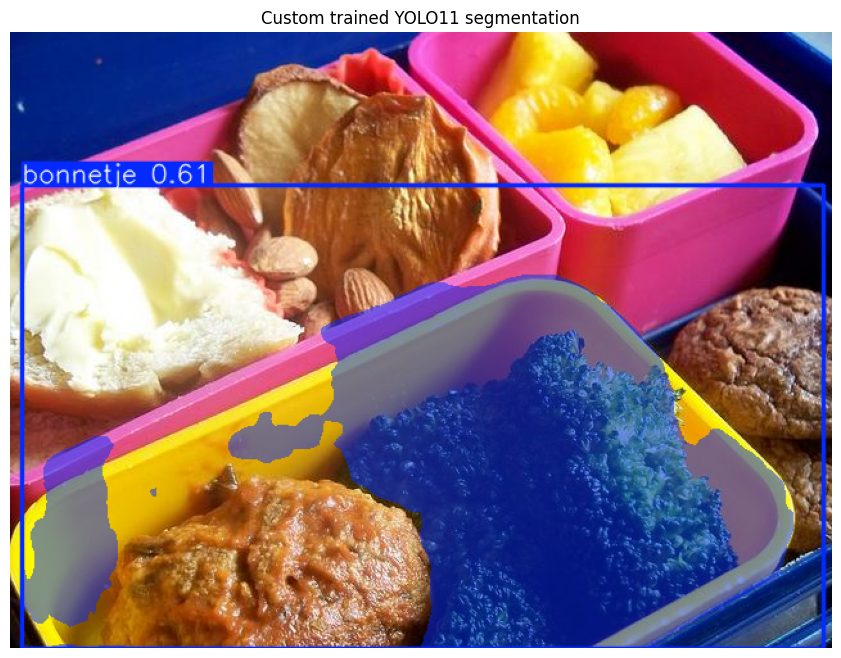

Object 1: bonnetje, confidence=0.615


In [21]:
uploaded = files.upload()  # Upload a new image
prediction_image = next(iter(uploaded.keys()))

predictions = trained_model.predict(
    source=prediction_image,
    imgsz=640,
    conf=0.25,
    iou=0.45,
    save=True
)

pred = predictions[0]
pred_image = pred.plot()

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(pred_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Custom trained YOLO11 segmentation")
plt.show()

if pred.boxes is not None:
    for i, box in enumerate(pred.boxes):
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        print(f"Object {i+1}: {trained_model.names[class_id]}, confidence={confidence:.3f}")
else:
    print("No objects detected.")

## 13. Save and download trained `.pt` model

In [22]:
OUTPUT_MODEL = "/content/my_trained_yolo11_seg.pt"
shutil.copy(BEST_MODEL_PATH, OUTPUT_MODEL)

print("Saved model:", OUTPUT_MODEL)
files.download(OUTPUT_MODEL)

Saved model: /content/my_trained_yolo11_seg.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Optional: export trained model to ONNX

In [23]:
onnx_path = trained_model.export(
    format="onnx",
    imgsz=640
)

print("ONNX export:", onnx_path)

Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n-seg summary (fused): 113 layers, 2,834,763 parameters, 0 gradients, 9.6 GFLOPs

PyTorch: starting from '/content/yolo_training/bonnetjes_custom/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) ((1, 37, 8400), (1, 32, 160, 160)) (5.7 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 251ms
Prepared 4 packages in 520ms
Installed 4 packages in 33ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.31.1
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 1.1s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onn

## Notes
- Use a GPU runtime for faster training.
- Ensure your dataset labels are segmentation polygons.
- If GPU memory is insufficient, reduce `batch=16` to `batch=8` or `batch=4`.
- Update `data.yaml` so its paths and class names match your dataset.
- The pretrained checkpoint may be specialized for receipts; fine-tuning on a very different task may require a suitable general segmentation checkpoint.
